# State-disentangled multi-tak learning framework for robust PPG-based biometric authentication on smartwatches

In [1]:
from pathlib import Path
import itertools
import random
import pickle
from datetime import datetime

import mne 

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt, find_peaks, resample

import torch.nn as nn
import torch.nn.functional as F

# data loading

In [7]:
# daily-activity 
SCIENTISST_SUBJECTS = ["3B8D", "AP3H", "4JF9", "JD3K", "K2Q2", "93DK", "H39D", "KF93", "LDM5", "03FH", "LAS2", "ME93", "3RFH", "F408", "LK27", "KS03"]
SCIENTISST_LOC = Path("data/scientisst-move/")
DALIA_SUBJECTS = [f"S{n}" for n in range(1, 16)]
DALIA_DATASET_LOC = Path("data/dalia/PPG_FieldStudy/")

# emotional-stress
COGWEAR_SUBJECTS = [x for x in range(25) if x != 19]
COGWEAR_DATASET_LOC = Path("data/cogwear")
ISSES_SUBJECTS = [f"S{x:02d}" for x in range(1, 19) if x != 2] + [f"f{x:02d}" for x in range(1, 19) if x not in [7, 14]]
ISSES_DATASET_LOC = Path("data/wearable-device-dataset/1.0.1/Wearable_Dataset/")


In [16]:
# daily-activity

def get_data_scientisst(subject: str) -> tuple[list[np.ndarray], list[np.ndarray], list[np.ndarray]]:
    datafile = SCIENTISST_LOC / subject / "empatica.edf"
    data = mne.io.read_raw_edf(datafile, verbose=False)

    baseline = [] # baseline
    walking = []  # walk_before walk_after walk_before_downstairs
    working = []  # greetings jumps lift run sprint lift-1 lift-2

    for annot in data.annotations:
        segment = data.get_data(picks="ppg:wrist", tmin=annot['onset'], tmax=annot['onset'] + annot['duration'])[0]
        if annot['description'] in ["baseline"]:
            baseline.append(segment)
        elif annot['description'] in ["walk_before", "walk_after", "walk_before_downstairs", "walk_before_elevatordown", "walk_before_elevatorup"]:
            walking.append(segment)
        elif annot['description'] in ["greetings", "jumps", "lift", "run", "sprint", "lift-1", "lift-2", "gesticulate"]:
            working.append(segment)
        else:
            print("weird annotation: " + annot['description'])

    return baseline, walking, working
            

def get_data_dalia(name: str) -> tuple[list[np.ndarray], list[np.ndarray], list[np.ndarray]]:

    datafile = DALIA_DATASET_LOC / name / f"{name}.pkl"
    data = pickle.load(open(datafile, "rb"), encoding="bytes")

    activity = data[b'activity']
    ppg = data[b'signal'][b'wrist'][b'BVP']

    # split into sections
    split_indices = np.where(activity[:-1] != activity[1:])[0]
    sections = np.split(ppg, split_indices * 16) # * 16 since acitivity is 4hz
    labels = activity[np.insert(split_indices, 0, 0)] # labels of each section
    
    baseline = [] # 1
    walking = [] # 7
    working = [] # 8, (3, 4, 5, 6)?

    for s, l in zip(sections, labels):
        #print(s, l)
        if l == 1:
            baseline.append(s)
        elif l == 7:
            walking.append(s)
        elif l == 8:
            working.append(s)

    return baseline, walking, working


# emotional-stress
def get_data_cogwear(id: int) -> tuple[list[np.ndarray], list[np.ndarray]]:

    def read_csv(file):
        return np.array([float(x.split(",")[0]) for x in open(file).readlines()[1:]])
               
        
    # ignoring the gameified dataset for right now

    if id <= 10:
        # non gamified 
        base_datafile = COGWEAR_DATASET_LOC / "pilot" / str(id) / "baseline" / "empatica_bvp.csv"
        stress_datafile = COGWEAR_DATASET_LOC / "pilot" / str(id) / "cognitive_load" / "empatica_bvp.csv"

        return [read_csv(base_datafile)], [read_csv(stress_datafile)]
        
    else:
        # gamified
        subject_dir = COGWEAR_DATASET_LOC / "survey_gamification" / str(id)

        subdirs = ["pre", "post"] if id not in [20, 21] else ["pre"]
        
        base_datafiles = [subject_dir / x / "baseline" / "empatica_bvp.csv" for x in subdirs]
        stress_datafiles = [subject_dir / x / "cognitive_load" / "empatica_bvp.csv" for x in subdirs]

        return [read_csv(x) for x in base_datafiles], [read_csv(x) for x in stress_datafiles]


def get_data_isses(name):
    
    folder = ISSES_DATASET_LOC / "STRESS" / name
    start_time, *data = open(folder / "BVP.csv").readlines()
    tags = open(folder / "tags.csv").readlines()

    start_time = int(datetime.strptime(start_time.strip(), "%Y-%m-%d %H:%M:%S").timestamp())
    tag_times = np.array([int(datetime.strptime(x.strip(), "%Y-%m-%d %H:%M:%S").timestamp()) for x in tags])

    split_times = (tag_times - start_time) * 64

    sections = np.split([float(x) for x in data], split_times)

    # check the isses ipynb on this stuff
    if name[0] == 'S':
        #1, 4, 6 -> base
        #3, 5, 7, 9, 11 -> stress
        return [sections[x] for x in [1, 4, 6]], [sections[x] for x in [3, 5, 7, 9, 11]]
    elif name[0] == 'f':

        # might be worth discarding section 0, as it contains weird funky data
        # from the start
        
        #0, 3, 7 -> base
        #2, 4, 6, 8 -> stress
         return [sections[x] for x in [0, 3, 7]], [sections[x] for x in [2, 4, 6, 8]]

    raise ValueError(f"idk who {name} is in isses")
    

In [4]:
daily_activity_dataset = [get_data_scientisst(x) for x in SCIENTISST_SUBJECTS] + \
                         [get_data_dalia(x) for x in DALIA_SUBJECTS]
print(f"loaded {len(daily_activity_dataset)} subjects into the daily activity dataset")

/tmp/ipykernel_5601/610252299.py:5: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  data = mne.io.read_raw_edf(datafile, verbose=False)


loaded 31 subjects into the daily activity dataset


In [17]:
emotional_stress_dataset = [get_data_cogwear(x) for x in COGWEAR_SUBJECTS] + \
                            [get_data_isses(x) for x in ISSES_SUBJECTS]
print(f"loaded {len(emotional_stress_dataset)} subjects into the emotional dataset")

loaded 57 subjects into the emotional dataset


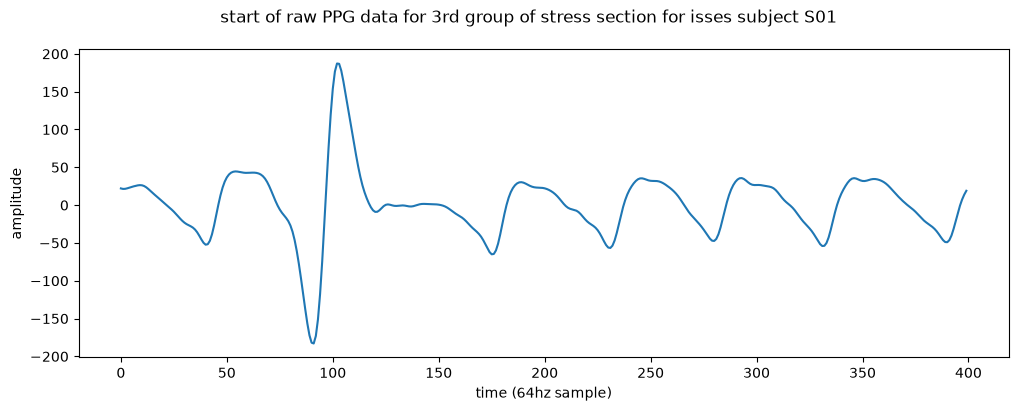

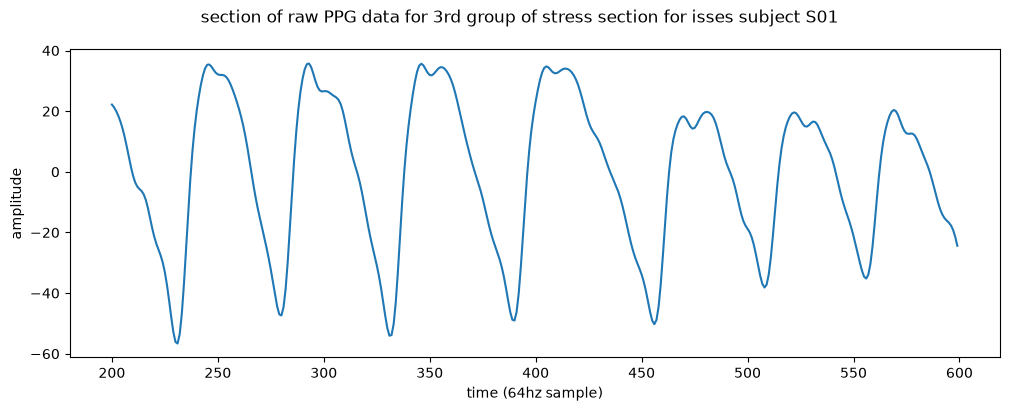

In [61]:
base, stress = get_data_isses("S01")
data = stress[3]

fig, ax = plt.subplots(figsize=(12, 4))

fig.suptitle("start of raw PPG data for 3rd group of stress section for isses subject S01")
ax.plot(data[0:400])
ax.set_ylabel("amplitude")
ax.set_xlabel("time (64hz sample)")

fig, ax = plt.subplots(figsize=(12, 4))

fig.suptitle("section of raw PPG data for 3rd group of stress section for isses subject S01")
ax.plot(np.arange(200, 600), data[200:600])
ax.set_ylabel("amplitude")
ax.set_xlabel("time (64hz sample)")

plt.show()

# preprocessing

In [56]:
BEAT_LENGTH = 100

def preprocess(data: np.ndarray, SAMPLE_RATE=64, SEGMENT_LEN=5):
    #  === 1. bandpass filtering and smoothing ===
    # butterworth filter
    BUTTER_FILTER = butter(3, [0.5, 5], btype="bandpass", fs=SAMPLE_RATE, output="sos")
    data = sosfiltfilt(BUTTER_FILTER, data)

    # rolling average
    # window size was not explicitly said 
    WINDOW_SIZE = 4 # chosen by an RSA private key generator
    data = np.convolve(data, np.ones(WINDOW_SIZE), "valid")

    # === 2. Candidate beat minima detection ==
    # find candidate minima w/ minimum dist 0.4fs
    MINIMA_DIST = round(SAMPLE_RATE * 0.4)
    minima_idx, _ = find_peaks(-data, distance=MINIMA_DIST)

    # === 3. Local-window verification (refinement)
    # further refine boundaries
    refined_boundary_set = []
    # for each peak
    for minima in minima_idx:
        # extract local window
        MINIMA_WINDOW_SIZE = round(SAMPLE_RATE * 0.1)
        val = data[minima]
        window = data[max(0, minima - MINIMA_WINDOW_SIZE):minima + MINIMA_WINDOW_SIZE]
        # if p is the minimum in the window
        if np.min(window) == val:
            # append
            refined_boundary_set.append(minima)

    # === 4. Beat segmentation ===
    # refined_boundary_set already has the bounds of the segments 

    # === 5. Beat-level quality assesment ===
    good_beats = []
    # for each beat
    for start, end in itertools.pairwise(refined_boundary_set):
        beat = data[start:end]
        
        # calculate heartrate
        heart_rate = 60 / SAMPLE_RATE * (end - start) 
        # count local maxima
        maxima_idx, _ = find_peaks(beat)
        num_maxima = len(maxima_idx)
        
        # skip if heartrate is > 120hz 
        if heart_rate >= 120:
            continue 
        
        # skip if more than two maximum
        if num_maxima > 2:
            continue 

        # normalize beat 
        low, high = np.min(beat), np.max(beat)
        beat = (beat - low) / (high - low)
        
        # resample
        beat = resample(beat, BEAT_LENGTH)

        # taper 
        # it's worth noting that they don't say how/what to taper by
        # i went for 10% at each end
        TAPER = np.ones(100)
        ramp = np.linspace(0, 1, 10, endpoint=False)
        TAPER[:10] = ramp; TAPER[-10:] = ramp[::-1]
        beat = TAPER * beat

        # done !
        good_beats.append(beat)

    # === 6. segment assembly ===
    # concatenate n good beats
    segments = []
    for i in range(len(good_beats) - SEGMENT_LEN):
        segments.append(np.concatenate(good_beats[i:i+SEGMENT_LEN], axis=0))
    return segments
    

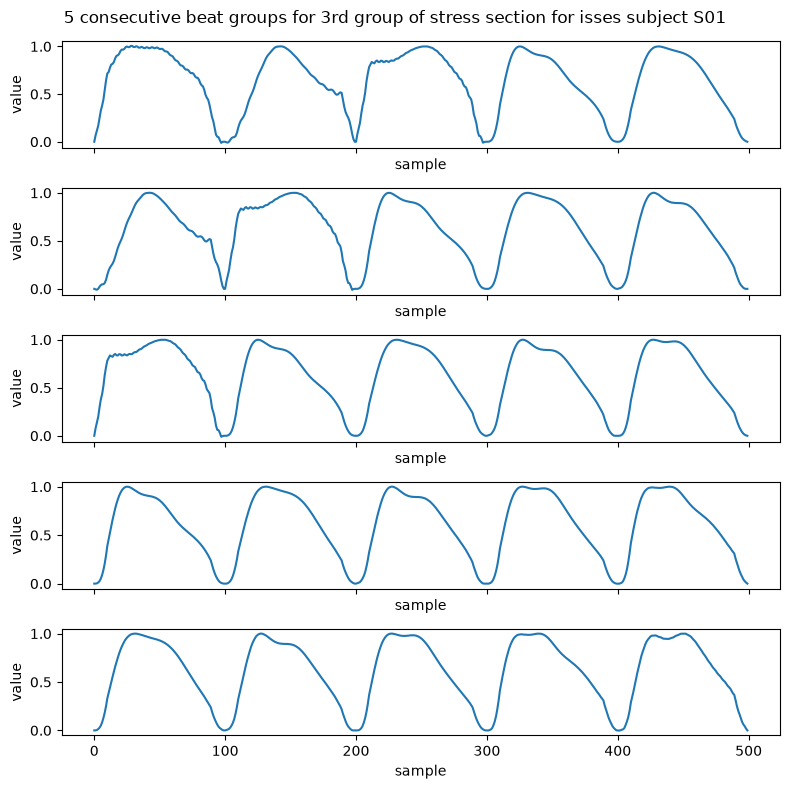

In [62]:
base, stress = get_data_isses("S01")
data = stress[3]

processed = preprocess(data, SAMPLE_RATE=64)

numbeats = 5

fig, axs = plt.subplots(numbeats, 1, sharex=True, figsize=(8,8), squeeze=False)
for segment, ax in zip(processed[0:], axs[:, 0]):
    ax.plot(segment)
    ax.set_xlabel("sample")
    ax.set_ylabel("value")

fig.suptitle("5 consecutive beat groups for 3rd group of stress section for isses subject S01")

plt.tight_layout()
plt.show()

# model itself

In [ ]:
class BottleneckBlock(nn.Module):
    """ bottleneck block """
    def __init__(self, in_channels=32, out_channels=32, dilation=1):
        super().__init__()
        
        mid_channels = in_channels // 2
        
        # reduction
        self.w1 = nn.Conv1d(
            in_channels=in_channels, 
            out_channels=mid_channels,
            kernel_size=1
        )

        # dwconv
        self.dwconv = nn.Conv1d(
            in_channels=mid_channels,
            out_channels=mid_channels,
            kernel_size=3,
            padding=dilation,
            dilation=dilation,
            groups=in_channels # makes it depthwise
        )

        # expansion
        self.w2 = nn.Conv1d(
            in_channels=mid_channels, 
            out_channels=out_channels,
            kernel_size=1
        )

    def forward(self, x):
        x = self.w11(x)
        x = self.dwconv(x)
        x = self.w2(x)
        return x

In [ ]:
class BeatEncoder(nn.Module):
    """ per-beat encoder """

    def __init__(self):
        super().__init__()

        self.initial_convolution = nn.Conv1d(
            in_channels=1, 
            out_channels=32, 
            kernel_size=3, 
            padding=1, # preserve legnth
            bias=False
        )

        # ===== bottlenecks =====
        self.bottleneck1 = BottleneckBlock(
            in_channels=32, 
            out_channels=32,
            dilation=1,
        )
        self.bottleneck2 = BottleneckBlock(
            in_channels=32,
            out_channels=64,
            dilation=2,
        )
        self.bottleneck3 = BottleneckBlock(
            in_channels=64,
            out_channels=128,
            dilation=4,
        )

        # ===== gating =====

        self.gate12 = nn.conv1d(in_channels=32, out_channels=64, kernel_size=1)
        self.gate23 = nn.conv1d(in_channels=64, out_channels=128, kernel_size=1)
        self.sigmoid = nn.Sigmoid()

        # ===== aggregation =====

        self.batch_normallization = nn.BatchNormalization(224)
        self.aggregate_conv = nn.Conv1d(in_channels=224, out_channels=128)
        self.gap = nn.AdaptiveAvgPool1d(1)

    def forward(self, f_init):

        # bottlenecks
        f_1 = self.bottleneck1(f_init)
        f_2 = self.bottleneck2(f_1)
        f_3 = self.bottleneck3(f_2)

        # gates
        f_2 = f_2 * self.sigmoid(
            self.gate12(f_1)
        )
        f_3 = f_3 * self.sigmoid(
            self.gate(f_2)
        )

        # aggreggation
        f_concat = torch.cat([f_1, f_2, f_3], dim=1)
        normed = self.bn(f_concat)
        compressed = self.aggregate_conv(normed)
        return self.gap(compressed).squeeze(-1)        

In [ ]:
class Encoder(nn.Module):
    """ the primary encoder for a group of beats"""
    
    def __init__(self, num_beats=5):
        super().__init__()

        self.num_beats = num_beats

        self.encoder = HDICNNBranch()
        self.dense = nn.Linear(128 * num_beats, out_features=64)

    def forward(self, beats):

        encoded = []
        for i in range(self.num_beats):
            encoded.append(
                self.encoder(beats[:, 0:100])
            )

        return self.dense(torch.concat(encoded, dim=1))
        
    

# the learning stuff